In [1]:
%load_ext autoreload
%autoreload 2

# Get parent directory and add to sys.path
import sys, os
parent_dir = os.path.dirname(os.getcwd())
sys.path.append(parent_dir)

# Require ipympl
%matplotlib widget 

In [2]:
import time
from LandMPC.MPCLandControl import MPCLandControl
from src.rocket import Rocket, perturb_rocket
from src.pos_rocket_vis import *

rocket_obj_path = os.path.join(parent_dir, "Simple_rocket.obj")
rocket_params_path = os.path.join(parent_dir,"rocket.yaml")

# Rocket setup
Ts  = 1/20
rocket = Rocket(Ts=Ts, model_params_filepath=rocket_params_path)
rocket.mass = 1.7 # Do not change!!!

# Visualization setup
vis = RocketVis(rocket, rocket_obj_path)
vis.anim_rate = 1


******************************************************************************
This program contains Ipopt, a library for large-scale nonlinear optimization.
 Ipopt is released as open source code under the Eclipse Public License (EPL).
         For more information visit https://github.com/coin-or/Ipopt
******************************************************************************

Linearization around a steady state:
x_ref =  [0 0 0 0 0 0 0 0 0 1 0 3]
xs =  [0. 0. 0. 0. 0. 0. 0. 0. 0. 1. 0. 3.]
us =  [ 0.          0.         56.66666667  0.        ]
Maximum invariant set successfully computed after 28 iterations. (from class MPCControl_x)
Maximum invariant set successfully computed after 33 iterations. (from class MPCControl_y)
Minimal robust invariant set computation converged after 61 iterations.
Maximum invariant set successfully computed after 30 iterations. (from class MPCControl_z)
Simulating time 0.00


c:\Users\marwa\anaconda3\envs\mpc2025\Lib\site-packages\cvxpy\reductions\solvers\solving_chain_utils.py:30: UserWarning: The problem includes expressions that don't support CPP backend. Defaulting to the SCIPY backend for canonicalization.
  warnings.warn(UserWarning(



 State alpha violation: 0.21 > 0.17, 
 State alpha violation: 0.22 > 0.17, 
 State alpha violation: 0.20 > 0.17, 
 State beta violation: -0.20 < -0.17, 
 State beta violation: -0.19 < -0.17, 
 State alpha violation: 0.18 > 0.17, 
 State alpha violation: 0.18 > 0.17, 
 State beta violation: -0.18 < -0.17, Simulating time 1.00
Simulating time 2.00
Simulating time 3.00
Simulating time 4.00
Simulating time 5.00
Simulating time 6.00
Simulating time 7.00
Simulating time 8.00
Simulating time 9.00
Simulating time 10.00
Simulating time 11.00
Simulating time 12.00
Simulating time 13.00
Simulating time 14.00
Simulating time 15.00
Simulating time 16.00
Simulating time 17.00
Simulating time 18.00
Simulating time 19.00


AppLayout(children=(HBox(children=(Play(value=0, description='Press play', max=399, step=2), IntSlider(value=0…

{'fig': <Figure size 640x480 with 16 Axes>,
 'axes': [<Axes: ylabel='inputs'>,
  <Axes: >,
  <Axes: >,
  <Axes: >,
  <Axes: title={'center': 'Subsystem Y'}>,
  <Axes: title={'center': 'Subsystem X'}, ylabel='$\\omega_{\\phi\\theta\\psi}$ (deg/s)'>,
  <Axes: title={'center': 'Subsystem Z'}>,
  <Axes: >,
  <Axes: ylabel='$\\phi\\theta\\psi$ (deg)'>,
  <Axes: title={'center': 'Subsystem Roll'}>,
  <Axes: ylabel='$v_{\\text{ENU}}$ (m/s)'>,
  <Axes: >,
  <Axes: >,
  <Axes: ylabel='$\\text{pos}_{\\text{ENU}}$ (m)'>,
  <Axes: >,
  <Axes: >],
 'plotter': <pyvista.plotting.plotter.Plotter at 0x1e0fe3b7e90>,
 'scene_objects': {'rocket_actor': Actor (0x1e0fe315420)
    Center:                     (2.9960132937952326, 2.0067969048223624, 10.642316000000001)
    Pickable:                   True
    Position:                   (0.0, 0.0, 0.0)
    Scale:                      (1.0, 1.0, 1.0)
    Visible:                    True
    X Bounds                    2.439E+00, 3.553E+00
    Y Bounds         

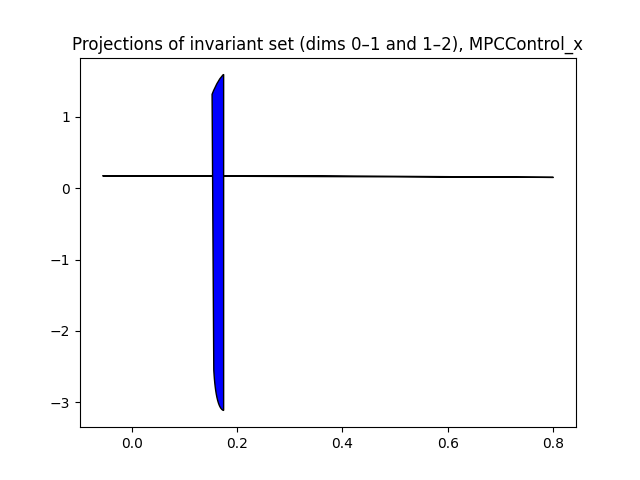

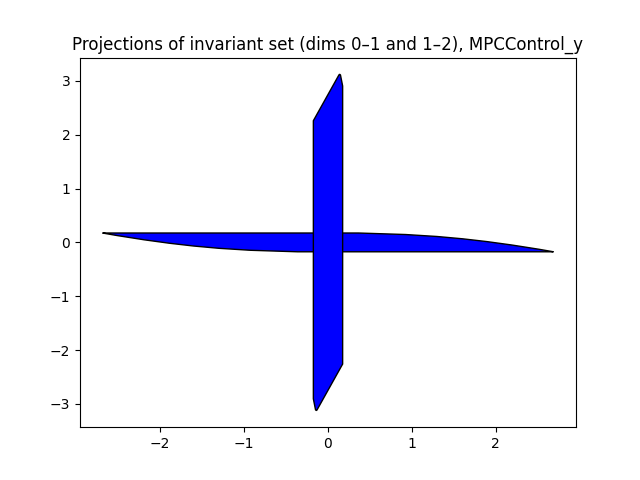

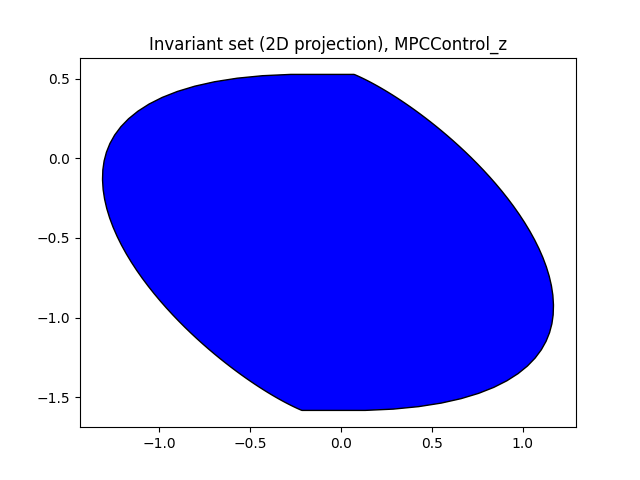

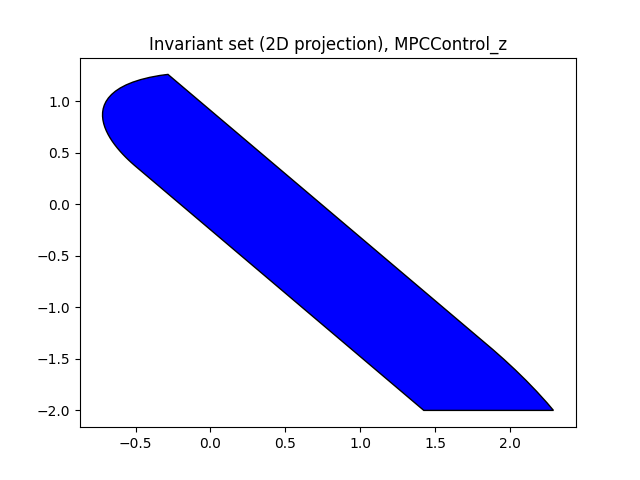

In [3]:
sim_time = 20  # simulation length in seconds
x0 = np.array([0, 0, 0, # omega => vitesse angulaaire
               0, 0, 0.5236, # phi => angle alpha beta gamma. 0.698 rad = 40 deg
               0, 0, 0, # Vitesses lin xyz. On part de 5m/s dans chaque direction
               3, 2, 10])# position xyz
x_ref = np.array([0, 0, 0, # omega => vitesse angulaaire
               0, 0, 0, # phi => angle alpha beta gamma. 0.698 rad = 40 deg
               0, 0, 0, # Vitesses lin xyz. On part de 5m/s dans chaque direction
               1, 0, 3])# position xyz
xs, us = rocket.trim(x_ref)
print("Linearization around a steady state:")
print("x_ref = ", x_ref)
print("xs = ", xs)
print("us = ", us)
A, B = rocket.linearize(xs, us)

# MPC parameters
H = 7
# Merge four linear mpc
mpc = MPCLandControl().new_controller(rocket, Ts, H, x_ref=x_ref)

t_cl, x_cl, u_cl, t_ol, x_ol, u_ol = rocket.simulate_land(mpc, sim_time, H, x0)
vis.animate(t_cl[:-1], x_cl[:,:-1], u_cl, T_ol=t_ol[...,:-1], X_ol=x_ol, U_ol=u_ol)

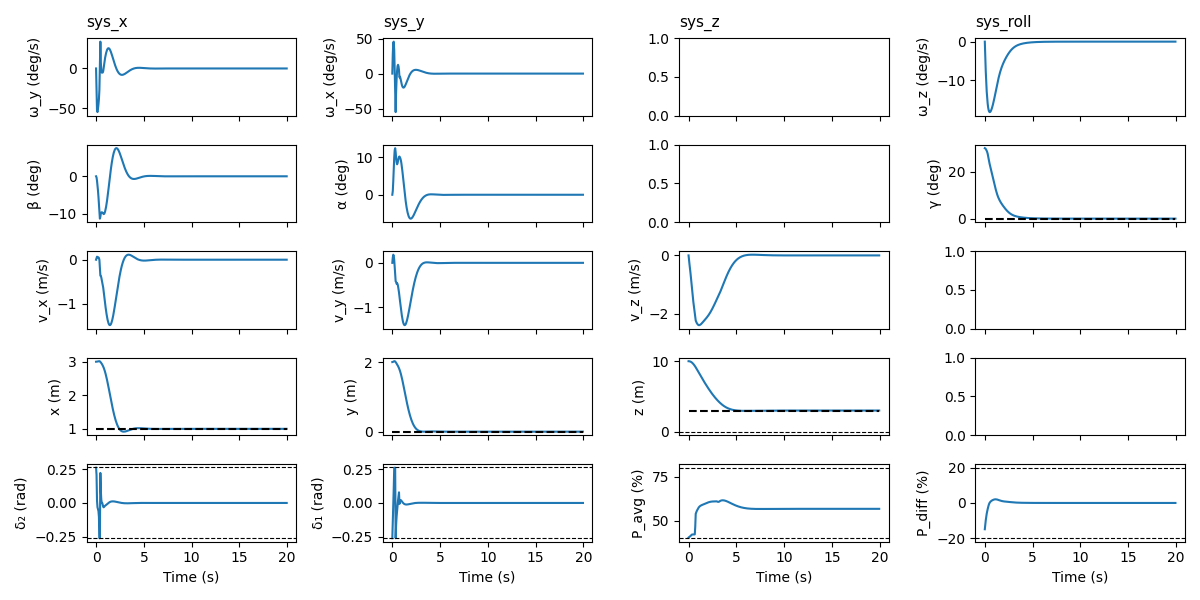

In [4]:
# Closed loop states and inputs plot
plot_static_states_inputs(t_cl[:-1], x_cl[:,:-1], u_cl, xs)